 # SUPER-MARKET SALES DATA ANALYSIS
 ## BUSINESS UNDERTSANDING

 ### 1.1 Business Problem

 Company XYZ operates three supermarket branches in Lagos, Abuja, and Port Harcourt. The company wants to understand its sales performance, customer purchasing behaviour, and overall business operations using transaction data collected between January and March 2019.

The business needs to identify which branches and products generate the most revenue, understand customer preferences and payment methods, and determine opportunities to improve sales and customer satisfaction.

The purpose of this analysis is to turn the available transaction data into useful insights that will help management make better business decisions, increase revenue, and improve operational efficiency.

 ### 1.2 Business Questions

1. Which supermarket branch generates the highest total sales revenue and gross income?
2. Which product lines generate the highest sales revenue and have the largest quantities sold?
3. How do sales change across January, February, and March 2019?
4. How does purchasing behaviour differ between Member and Normal customers, and between male and female customers?
5. Which payment method is most frequently used by customers across the three branches?

Additional questions:

6. At what times of the day do supermarkets experience the highest number of transactions?
7. Which supermarket branch receives the highest average customer satisfaction rating?
8. Are sales higher during weekdays or weekends?

 ### 1.3 Assumptions and Limitations

 1. Limited time period

The dataset covers only three months, from January to March 2019. Therefore, the findings may not fully represent annual sales performance, seasonal trends, or customer behaviour throughout the year.

2. Limited customer information

The dataset contains information such as customer type and gender, but does not include detailed customer profiles or unique customer identifiers. This limits the ability to analyse individual customer loyalty, repeat purchases, and long-term purchasing behaviour.

3. Data accuracy and completeness

The analysis assumes that the recorded transactions, prices, quantities, payment methods, and customer ratings are accurate. Any missing values, duplicate transactions, or incorrect entries could affect the reliability of the findings and conclusions.

 ## 2. DATA LOADING AND INSPECTION

👇 Importing Pandas

I imported Pandas to help me work with and analyze my dataset.

In [3]:
import pandas as pd


👇 Checking if the File Exists

I checked if the Lagos Branch CSV file was available in the specified location.

In [5]:
import os
print(os.path.exists("/Lagos_Branch.csv"))

False


👇 Connecting Google Drive

I connected my Google Drive to Google Colab so I could access my supermarket sales files.

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


👇 Checking My Files

I checked the files in my Google Drive to locate the supermarket sales datasets.

In [8]:
import os
print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'David John photo .png', 'VIRTUAL ASSISTANT FILE ', 'BENIN PASSPORT ', 'David John AI DATA ANNOTATION SPECIALIST .pdf', 'David John Tech. Support Resume .pdf', 'My Documents', 'DAVID JOHN - INTERNATIONAL PASSPORT .pdf', 'Internet speed .JPG', 'Screenshot 2026-01-02 203009.png', 'COMPANY INFORMATION ', 'DAVID. E. JOHN | CV.pdf', 'DAVID E. JOHN Executive  Assistant Resume. (1).pdf', 'DAVID E. JOHN Executive  Assistant Resume..pdf', 'David John Cover Letter .pdf', 'd950bc63-03a5-4b2c-addd-6784a94fe132.jpeg', 'David John Record of Answers .m4a', 'Backup-codes-david.txt', 'David John image .png', 'David_John_Customer_Support_Manager_Resume.docx', 'David John Executive Resume.pdf', 'Mr. Chad Work', 'GLM LIBRARY.gsheet', 'Automotive Content Planner - Block Layout V9.xlsx', 'Corporate Career Briefing.gdoc', 'Port_Harcourt_Branch.csv', 'Lagos_Branch.csv', 'Abuja_Branch.csv']


👇 Loading the Supermarket Datasets

I loaded the Lagos, Abuja and Port Harcourt CSV files into Pandas so I could work with their sales data.

In [9]:
lagos = pd.read_csv('/content/drive/MyDrive/Lagos_Branch.csv')

abuja = pd.read_csv('/content/drive/MyDrive/Abuja_Branch.csv')

port_harcourt = pd.read_csv('/content/drive/MyDrive/Port_Harcourt_Branch.csv')

👇 Combining the Datasets

I combined the Lagos, Abuja and Port Harcourt datasets into one table so I could analyze all the supermarket sales together.


In [10]:
df = pd.concat([lagos, abuja, port_harcourt], ignore_index=True)

👇 Viewing the First Five Rows

I displayed the first five rows to see what the combined dataset looks like.

In [11]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Lagos,Member,Female,Health and beauty,26888.4,7,9410.94,197629.74,1/5/2019,13:08,Epay,188218.8,4.761905,9410.94,9.1
1,631-41-3108,A,Lagos,Normal,Male,Home and lifestyle,16678.8,7,5837.58,122589.18,3/3/2019,13:23,Card,116751.6,4.761905,5837.58,7.4
2,123-19-1176,A,Lagos,Member,Male,Health and beauty,20959.2,8,8383.68,176057.28,1/27/2019,20:33,Epay,167673.6,4.761905,8383.68,8.4
3,373-73-7910,A,Lagos,Normal,Male,Sports and travel,31071.6,7,10875.06,228376.26,2/8/2019,10:37,Epay,217501.2,4.761905,10875.06,5.3
4,355-53-5943,A,Lagos,Member,Female,Electronic accessories,24782.4,6,7434.72,156129.12,2/25/2019,14:36,Epay,148694.4,4.761905,7434.72,5.8


👇 Viewing the Last Five Rows

I displayed the last five rows to check the records at the end of my dataset.

In [12]:
df.tail()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
995,148-41-7930,C,Port Harcourt,Normal,Male,Health and beauty,35985.6,7,12594.96,264494.16,1/23/2019,10:33,Cash,251899.2,4.761905,12594.96,6.1
996,189-40-5216,C,Port Harcourt,Normal,Male,Electronic accessories,34693.2,7,12142.62,254995.02,1/9/2019,11:40,Cash,242852.4,4.761905,12142.62,6.0
997,267-62-7380,C,Port Harcourt,Member,Male,Electronic accessories,29642.4,10,14821.20,311245.20,3/29/2019,19:12,Epay,296424.0,4.761905,14821.20,4.3
998,652-49-6720,C,Port Harcourt,Member,Female,Electronic accessories,21942.0,1,1097.10,23039.10,2/18/2019,11:40,Epay,21942.0,4.761905,1097.10,5.9
999,233-67-5758,C,Port Harcourt,Normal,Male,Health and beauty,14526.0,1,726.30,15252.30,1/29/2019,13:46,Epay,14526.0,4.761905,726.30,6.2


👇 Checking the Dataset Size

I checked the size of my dataset. It contains 1,000 rows and 17 columns.

In [13]:
df.shape

(1000, 17)

👇 Checking the Column Names

I checked the names of all the columns to understand the information available in my dataset.

In [14]:
df.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date',
       'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income',
       'Rating'],
      dtype='object')

👇 Checking the Data Types

I checked the data type of each column to know which ones contain numbers and which ones contain text.

In [15]:
df.dtypes

,0
Invoice ID,object
Branch,object
City,object
Customer type,object
Gender,object
Product line,object
Unit price,float64
Quantity,int64
Tax 5%,float64
Total,float64


👇 Checking the Dataset Information

I checked the dataset to see the number of rows, columns, data types and whether any values were missing.

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

👇 Checking the Statistical Summary

I used this code to see a summary of the numerical data, including the average, minimum, maximum and other important values.

In [17]:
df.describe()

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1000.000000,1000.00000
mean,20041.966800,5.510000,5536.572840,116268.029640,110731.456800,4.761905e+00,5536.572840,6.97270
std,9538.066205,2.923431,4215.177173,88518.720636,84303.543463,6.131498e-14,4215.177173,1.71858
min,3628.800000,1.000000,183.060000,3844.260000,3661.200000,4.761905e+00,183.060000,4.00000
25%,11835.000000,3.000000,2132.955000,44792.055000,42659.100000,4.761905e+00,2132.955000,5.50000
50%,19882.800000,5.000000,4351.680000,91385.280000,87033.600000,4.761905e+00,4351.680000,7.00000
75%,28056.600000,8.000000,8080.290000,169686.090000,161605.800000,4.761905e+00,8080.290000,8.50000
max,35985.600000,10.000000,17874.000000,375354.000000,357480.000000,4.761905e+00,17874.000000,10.00000


👇 Checking for Missing Values

I checked whether any columns had missing values. The result showed 0 for every column, meaning there were no missing values.

In [18]:
df.isnull().sum()

,0
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Total,0


👇 Checking for Duplicate Rows

I checked whether any rows were repeated in my dataset. The result was 0, meaning there were no duplicate rows.

In [19]:
df.duplicated().sum()

np.int64(0)

👇 Reviewing the Dataset

I reviewed the column names, data types, dataset information, statistical summary, missing values and duplicates to make sure my data was ready for analysis.

In [20]:
df.columns
df.dtypes
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

np.int64(0)

Part B: Data Loading and Inspection — Findings

The Lagos, Abuja, and Port Harcourt datasets were loaded using Pandas and combined into a single DataFrame.

The combined dataset contains 1,000 transaction records and 17 columns.

Initial inspection showed eight numerical columns and nine object-type columns. The average quantity purchased per transaction was 5.51 units, while the average customer rating was approximately 6.97.

There were no missing values or exact duplicate records in the dataset.

However, the Date and Time columns were identified as object data types, indicating that they require conversion before conducting time-based analysis.

In [21]:
df["Date"] = pd.to_datetime(df["Date"])

In [22]:
df["Date"].dtype

dtype('<M8[ns]')

In [23]:
df["Month"] = df["Date"].dt.month_name()

In [24]:
df["Day of Week"] = df["Date"].dt.day_name()

In [25]:
df["Hour"] = pd.to_datetime(df["Time"], format="%H:%M", errors="coerce").dt.hour

In [26]:
df[["Date", "Month", "Day of Week", "Time", "Hour"]].head()

,Date,Month,Day of Week,Time,Hour
0,2019-01-05,January,Saturday,13:08,13
1,2019-03-03,March,Sunday,13:23,13
2,2019-01-27,January,Sunday,20:33,20
3,2019-02-08,February,Friday,10:37,10
4,2019-02-25,February,Monday,14:36,14


In [27]:
df["Day Type"] = df["Day of Week"].apply(
    lambda day: "Weekend" if day in ["Saturday", "Sunday"] else "Weekday"
)

In [28]:
df[["Date", "Day of Week", "Day Type"]].head()

,Date,Day of Week,Day Type
0,2019-01-05,Saturday,Weekend
1,2019-03-03,Sunday,Weekend
2,2019-01-27,Sunday,Weekend
3,2019-02-08,Friday,Weekday
4,2019-02-25,Monday,Weekday


In [29]:
df[["Month", "Day of Week", "Hour", "Day Type"]].isnull().sum()

,0
Month,0
Day of Week,0
Hour,0
Day Type,0


In [30]:
df["Month"].unique()

array(['January', 'March', 'February'], dtype=object)

In [31]:
df["Day Type"].value_counts()

,count
Day Type,
Weekday,703
Weekend,297


In [32]:
df["Total"].sum()

np.float64(116268029.64)

In [33]:
df["Total"].mean()

np.float64(116268.02964)

In [34]:
df["Invoice ID"].count()

np.int64(1000)

In [35]:
df.groupby("City")["Total"].sum()

,Total
City,
Abuja,38231161.92
Lagos,38232133.38
Port Harcourt,39804734.34


In [36]:
df.groupby("City")["Total"].sum().sort_values(ascending=False)

,Total
City,
Port Harcourt,39804734.34
Lagos,38232133.38
Abuja,38231161.92


In [37]:
df.groupby("City")["Invoice ID"].count()

,Invoice ID
City,
Abuja,332
Lagos,340
Port Harcourt,328


In [38]:
df.groupby("Product line")["Total"].sum()

,Total
Product line,
Electronic accessories,19561511.34
Fashion accessories,19550122.20
Food and beverages,20212143.84
Health and beauty,17709746.04
Home and lifestyle,19390288.68
Sports and travel,19844217.54


In [39]:
df.groupby("Product line")["Total"].sum().sort_values(ascending=False)

,Total
Product line,
Food and beverages,20212143.84
Sports and travel,19844217.54
Electronic accessories,19561511.34
Fashion accessories,19550122.20
Home and lifestyle,19390288.68
Health and beauty,17709746.04


In [40]:
df["Product line"].value_counts()

,count
Product line,
Fashion accessories,178
Food and beverages,174
Electronic accessories,170
Sports and travel,166
Home and lifestyle,160
Health and beauty,152


In [41]:
df.groupby("Month")["Total"].sum()

,Total
Month,
February,34998974.64
January,41865072.48
March,39403982.52


In [42]:
monthly_sales = df.groupby("Month")["Total"].sum()

monthly_sales = monthly_sales.reindex(["January", "February", "March"])

monthly_sales

,Total
Month,
January,41865072.48
February,34998974.64
March,39403982.52


Monthly Supermarket Sales Analysis

The chart shows the total supermarket sales for January, February, and March.

January recorded the highest sales, with approximately 41.9 million. Sales dropped in February to approximately 35 million before increasing again in March to approximately 39.4 million.

This shows that supermarket sales fluctuated during the three months. Although sales improved in March, they did not reach the level recorded in January.

Conclusion: January was the best-performing month, while February had the lowest sales. The supermarket should investigate what caused the decline in February and identify ways to maintain consistent sales performance **bold text**

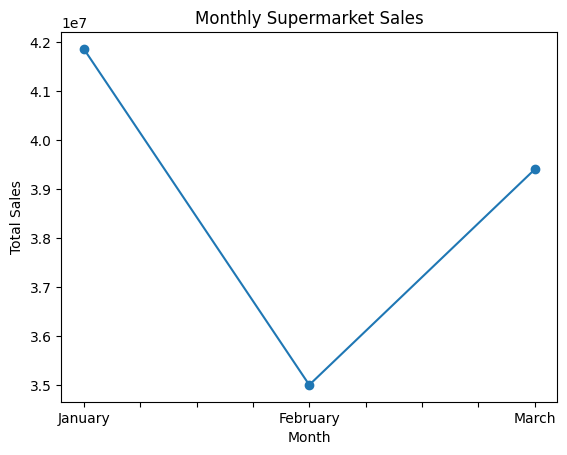

In [43]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Supermarket Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

In [44]:
df["Customer type"].value_counts()

,count
Customer type,
Member,501
Normal,499


In [45]:
df.groupby("Customer type")["Total"].sum()

,Total
Customer type,
Member,59120439.84
Normal,57147589.80


Sales by Customer Type

From the chart, we can see that members made more purchases than normal customers. Members recorded total sales of about 59.1 million, while normal customers recorded about 57.1 million.

The difference is not very big, but it shows that members contributed slightly more to the supermarket’s total sales.

This suggests that the membership programme may be helping the supermarket generate sales. The supermarket can encourage more customers to become members by offering discounts, rewards, or special promotions.

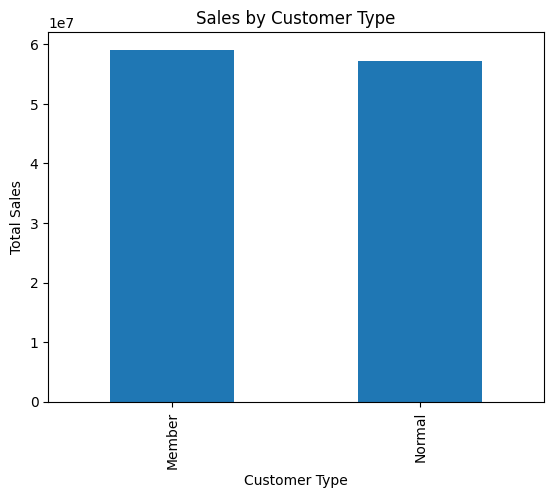

In [46]:
customer_sales = df.groupby("Customer type")["Total"].sum()

customer_sales.plot(kind="bar")

plt.title("Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Sales")
plt.show()

In [47]:
df["Payment"].value_counts()

,count
Payment,
Epay,345
Cash,344
Card,311


In [48]:
df.groupby("Payment")["Total"].sum()

,Total
Payment,
Card,36276145.92
Cash,40394365.20
Epay,39597518.52


In [73]:
df.groupby(["Branch", "Payment"])["Invoice ID"].count()

Branch  Payment
A       Card       104
        Cash       110
        Epay       126
B       Card       109
        Cash       110
        Epay       113
C       Card        98
        Cash       124
        Epay       106
Name: Invoice ID, dtype: int64

Sales by Payment Method

From the chart, we can see that cash payments recorded the highest sales, with about 40.4 million, followed by ePay with about 39.6 million. Card payments recorded the lowest sales, with about 36.3 million.

This shows that customers used all three payment methods, but cash contributed the most to total sales. The difference between cash and ePay was not very large, which also shows that electronic payments are popular among customers.

The supermarket should continue providing all three payment options so customers can pay using whichever method is most convenient for them.

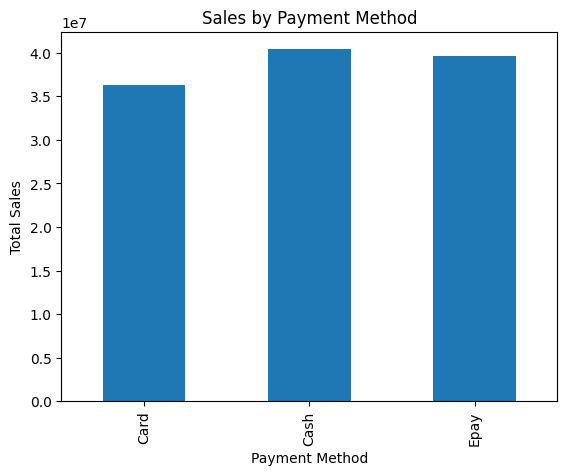

In [49]:
payment_sales = df.groupby("Payment")["Total"].sum()

payment_sales.plot(kind="bar")

plt.title("Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.show()

In [50]:
df.groupby("Day of Week")["Total"].sum()

,Total
Day of Week,
Friday,15813482.58
Monday,13643668.08
Saturday,20203491.42
Sunday,16004841.30
Thursday,16325729.28
Tuesday,18533608.38
Wednesday,15743208.60


In [51]:
df.groupby("Day of Week")["Total"].sum().sort_values(ascending=False)

,Total
Day of Week,
Saturday,20203491.42
Tuesday,18533608.38
Thursday,16325729.28
Sunday,16004841.30
Friday,15813482.58
Wednesday,15743208.60
Monday,13643668.08


Sales by Day of the Week

From the chart, we can see that Saturday recorded the highest sales, with about 20.2 million, followed by Sunday with about 16 million. Monday had the lowest sales, with about 13.6 million.

This shows that sales were higher on some days than others, with Saturday being the busiest day in terms of total sales. This could be because more customers have time to shop during the weekend.

The supermarket can use this information to prepare for busy days by making sure there are enough products available and enough staff to attend to customers. **bold text**

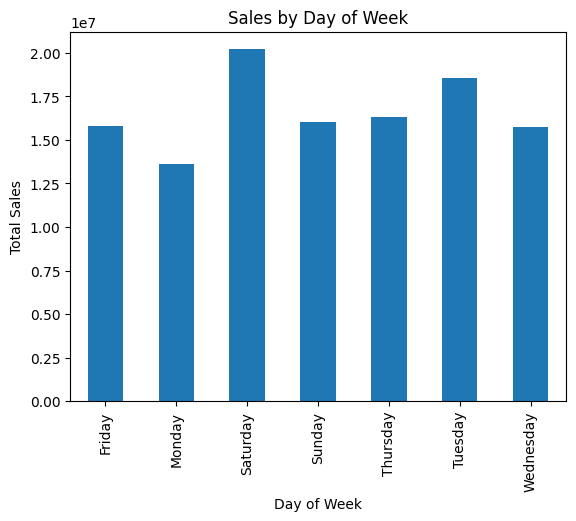

In [52]:
daily_sales = df.groupby("Day of Week")["Total"].sum()

daily_sales.plot(kind="bar")

plt.title("Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Total Sales")
plt.show()

In [53]:
df.groupby("Day Type")["Total"].sum()

,Total
Day Type,
Weekday,80059696.92
Weekend,36208332.72


Weekend vs Weekday Sales

From the chart, we can see that weekdays recorded higher total sales of about 80.1 million, while weekends recorded about 36.2 million.

This shows that the supermarket made more money during weekdays than weekends. However, there are five weekdays compared to two weekend days, which could explain why weekday sales were higher overall.

The supermarket should continue paying attention to both weekdays and weekends to understand customer shopping patterns and plan its operations better. **bold text**

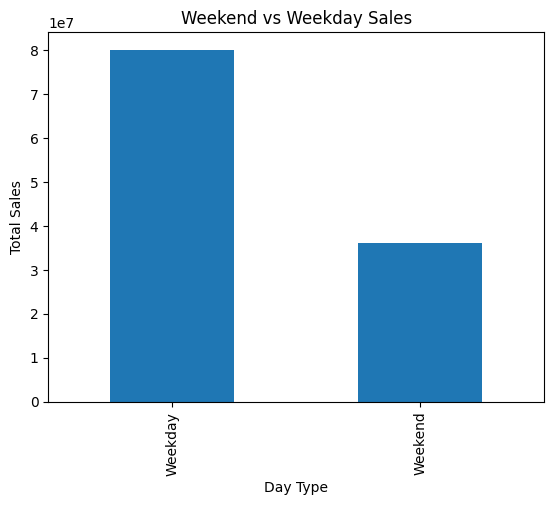

In [54]:
day_type_sales = df.groupby("Day Type")["Total"].sum()

day_type_sales.plot(kind="bar")

plt.title("Weekend vs Weekday Sales")
plt.xlabel("Day Type")
plt.ylabel("Total Sales")
plt.show()

In [55]:
df.groupby("Day Type")["Total"].mean()

,Total
Day Type,
Weekday,113882.925917
Weekend,121913.578182


Average Sales: Weekday vs Weekend

From the chart, we can see that weekends recorded a higher average transaction value of about 121,914, while weekdays recorded about 113,883.

This means that although the supermarket made more total sales during weekdays, customers spent more per transaction on weekends.

This could be because some customers prefer to do their bigger shopping during the weekend when they have more free time.

The supermarket can use this information to introduce weekend promotions and encourage customers to buy more products. **bold text**

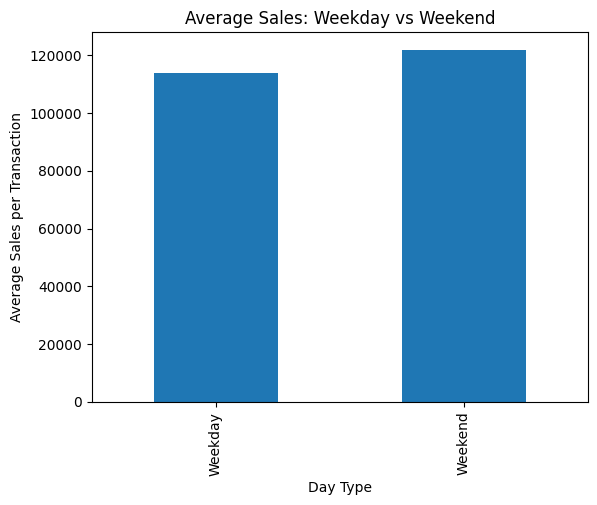

In [56]:
average_sales = df.groupby("Day Type")["Total"].mean()

average_sales.plot(kind="bar")

plt.title("Average Sales: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Sales per Transaction")
plt.show()

In [57]:
df.groupby("Hour")["Total"].sum()

,Total
Hour,
10,11311733.16
11,10935838.62
12,9383717.70
13,12500361.72
14,11098223.64
15,11224623.06
16,9081476.46
17,8800278.48
18,9370922.40


In [74]:
df.groupby("Hour")["Total"].mean().sort_values(ascending=False)

,Total
Hour,
14,133713.537831
19,126476.324602
11,121509.318000
13,121362.735146
17,118922.682162
16,117941.252727
10,111997.358020
20,110253.729600
15,110045.324118


Supermarket Sales by Hour

From the chart, we can see that supermarket sales were not the same throughout the day. Some hours recorded higher sales, while others recorded lower sales.

This shows that customers tend to shop more during certain hours of the day. The supermarket can use this information to understand its busy periods and prepare better.

For example, the supermarket can make sure there are enough staff available during the hours with higher sales and that popular products are well stocked to meet customer demand. **bold text**

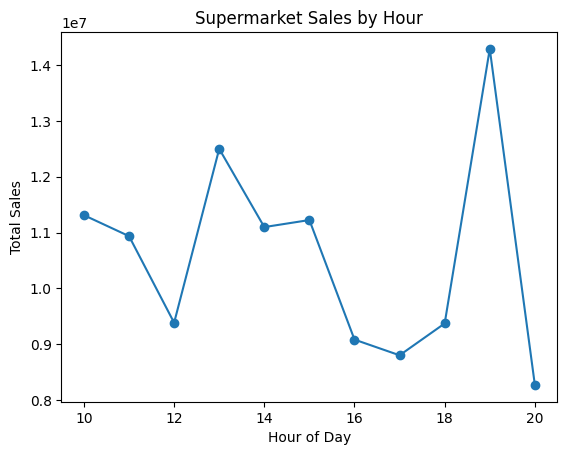

In [59]:
hourly_sales = df.groupby("Hour")["Total"].sum()

hourly_sales.plot(kind="line", marker="o")

plt.title("Supermarket Sales by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Total Sales")
plt.show()

In [60]:
df.groupby("Hour")["Invoice ID"].count().sort_values(ascending=False)

,Invoice ID
Hour,
19,113
13,103
15,102
10,101
18,93
11,90
12,89
14,83
16,77


Number of Transactions by Hour

From the chart, we can see that the number of transactions changes throughout the day. Some hours recorded more transactions than others, which shows that customers shop more frequently at certain times.

This helps us understand when the supermarket is likely to be busier. The supermarket can use this information to make sure enough staff are available during busy hours so customers don’t have to wait too long to be attended to.

It can also help the supermarket plan its activities during quieter hours.

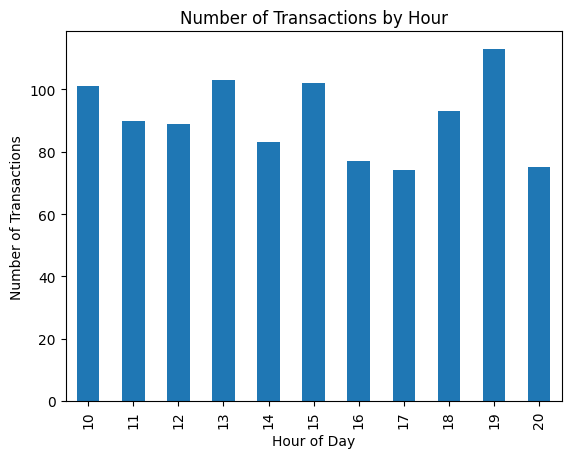

In [61]:
hourly_transactions = df.groupby("Hour")["Invoice ID"].count()

hourly_transactions.plot(kind="bar")

plt.title("Number of Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.show()

Average Transaction Value by Hour

From the chart, we can see that the average amount customers spent per transaction was different throughout the day. Some hours had a higher average transaction value, while others had a lower average.

This means that customers spent more money per purchase during certain hours, even if those hours did not necessarily have the highest number of transactions.

The supermarket can use this information to understand customers’ spending patterns and identify the hours when customers tend to make bigger purchases. This could also help the supermarket plan promotions at different times of the day.

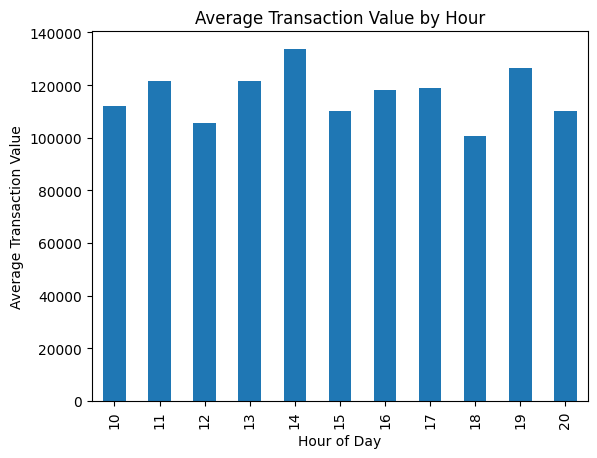

In [63]:
average_hourly_sales = df.groupby("Hour")["Total"].mean()

average_hourly_sales.plot(kind="bar")

plt.title("Average Transaction Value by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Transaction Value")
plt.show()

In [75]:
df.groupby(["Branch", "Hour"])["Invoice ID"].count()

Branch  Hour
A       10      38
        11      35
        12      33
        13      31
        14      25
        15      37
        16      32
        17      27
        18      33
        19      27
        20      22
B       10      26
        11      33
        12      25
        13      38
        14      30
        15      32
        16      17
        17      20
        18      35
        19      50
        20      26
C       10      37
        11      22
        12      31
        13      34
        14      28
        15      33
        16      28
        17      27
        18      25
        19      36
        20      27
Name: Invoice ID, dtype: int64

In [76]:
hourly_transactions = df.groupby(["Branch", "Hour"])["Invoice ID"].count()

hourly_transactions.groupby(level=0).idxmax()

,Invoice ID
Branch,
A,"(A, 10)"
B,"(B, 19)"
C,"(C, 10)"


In [64]:
df.groupby("City")["Total"].mean().sort_values(ascending=False)

,Total
City,
Port Harcourt,121355.897378
Abuja,115154.102169
Lagos,112447.451118


Average Transaction Value by City

From the chart, we can see that Port Harcourt recorded the highest average transaction value of about 121,356, followed by Abuja with about 115,154. Lagos recorded the lowest average transaction value of about 112,447.

This shows that customers in Port Harcourt spent more money per transaction compared to customers in Abuja and Lagos.

Although Lagos had the lowest average transaction value, it does not mean the supermarket performed badly there. It simply means customers spent less on average each time they made a purchase.

The supermarket can use this information to understand spending patterns in each city and find ways to encourage customers to spend more per purchase.

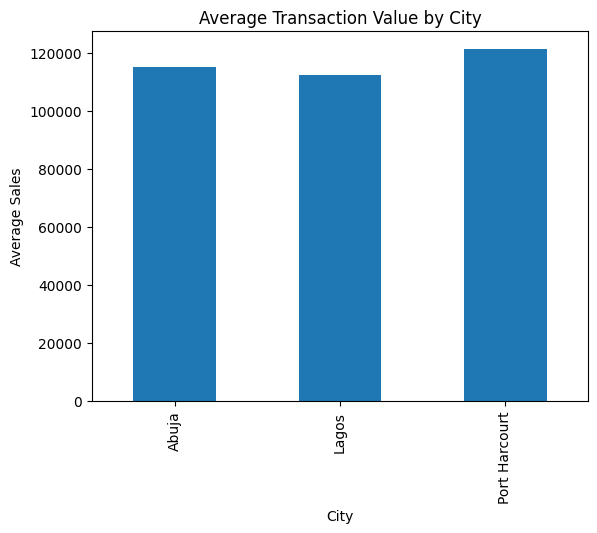

In [65]:
city_average = df.groupby("City")["Total"].mean()

city_average.plot(kind="bar")

plt.title("Average Transaction Value by City")
plt.xlabel("City")
plt.ylabel("Average Sales")
plt.show()

**Branch C generates the highest gross income, followed by Branch A and Branch B. This shows that Branch C contributes the most gross income among the three branches.**

In [66]:
df.groupby("Branch")["gross income"].sum().sort_values(ascending=False)

,gross income
Branch,
C,1895463.54
A,1820577.78
B,1820531.52


**January recorded the highest total sales, followed by March, while February had the lowest sales.**

In [67]:
df.groupby("Month")["Total"].sum()

,Total
Month,
February,34998974.64
January,41865072.48
March,39403982.52


**Food and beverages generated the highest total sales, while Health and beauty generated the lowest total sales among the six product lines.**

In [68]:
df.groupby("Product line")["Total"].sum().sort_values(ascending=False)

,Total
Product line,
Food and beverages,20212143.84
Sports and travel,19844217.54
Electronic accessories,19561511.34
Fashion accessories,19550122.20
Home and lifestyle,19390288.68
Health and beauty,17709746.04


👇 Checking Quantity Sold by Product Line

I grouped the products by category to find out which product line sold the highest number of items.

In [72]:
df.groupby("Product line")["Quantity"].sum().sort_values(ascending=False)

,Quantity
Product line,
Electronic accessories,971
Food and beverages,952
Sports and travel,920
Home and lifestyle,911
Fashion accessories,902
Health and beauty,854


👇 Comparing Quantity Sold and Total Sales

I compared the quantity sold and total sales for each product line to see whether the products with the highest quantity also generated the highest revenue.

In [79]:
df.groupby("Product line")[["Quantity", "Total"]].sum().sort_values(by="Quantity", ascending=False)

,Quantity,Total
Product line,,
Electronic accessories,971,19561511.34
Food and beverages,952,20212143.84
Sports and travel,920,19844217.54
Home and lifestyle,911,19390288.68
Fashion accessories,902,19550122.20
Health and beauty,854,17709746.04


**Female customers contributed more to total supermarket sales than male customers.**

In [69]:
df.groupby("Gender")["Total"].sum()

,Total
Gender,
Female,60437853.00
Male,55830176.64


👇 Checking Average Customer Ratings by Branch

I calculated the average customer rating for each branch to find out which branch received the best ratings from customers.

In [70]:
df.groupby("Branch")["Rating"].mean()

,Rating
Branch,
A,7.027059
B,6.818072
C,7.072866


👇 Checking the Relationship Between Customer Ratings and Sales

I checked whether there is a relationship between customer ratings, total sales and gross income.

From my analysis, I found that the correlation between customer ratings and total sales was -0.0364, which is very close to zero.

This shows that there is almost no relationship between how much customers spend and the ratings they give. Customers who spend more do not necessarily give higher ratings.

In [77]:
df[["Rating", "Total", "gross income"]].corr()

,Rating,Total,gross income
Rating,1.000000,-0.036442,-0.036442
Total,-0.036442,1.000000,1.000000
gross income,-0.036442,1.000000,1.000000


👇 Identifying the Highest-Value Customer Segments

I grouped customers by branch, gender and customer type to find out which group contributed the most to total supermarket sales.

In [78]:
df.groupby(["Branch", "Gender", "Customer type"])["Total"].sum().sort_values(ascending=False)

Branch  Gender  Customer type
C       Female  Member           12475239.84
                Normal            9731526.84
A       Male    Member            9717986.88
B       Male    Member            9667531.44
        Female  Member            9666155.52
C       Male    Normal            9595945.80
A       Female  Member            9591504.30
                Normal            9585395.82
B       Male    Normal            9509444.28
        Female  Normal            9388030.68
A       Male    Normal            9337246.38
C       Male    Member            8002021.86
Name: Total, dtype: float64

 ## KEY FINDINGS

From my analysis of the supermarket sales data, I discovered the following:

1. Monthly Sales: January recorded the highest sales at about 41.9 million, followed by March at 39.4 million. February had the lowest sales at about 35 million.
2. Branch Performance: Port Harcourt generated the highest total sales, while Branch C recorded the highest gross income.
3. Product Performance: Food and Beverages generated the highest revenue, while Health and Beauty generated the lowest.
4. Customer Type: Members generated about 59.1 million in sales, compared to 57.1 million from normal customers.
5. Payment Methods: ePay was the most frequently used payment method, with 345 transactions. However, cash generated the highest total sales.
6. Shopping Patterns: Weekdays generated more total sales than weekends, but customers spent more per transaction during weekends.
7. Customer Ratings: Branch C had the highest average customer rating, followed by Branch A and Branch B.
8. Ratings and Spending: I found almost no relationship between customer ratings and the amount customers spent.

 ## BUSINESS RECOMMENDATIONS

Based on my findings, I recommend the following actions:

1. Improve Product Availability — High Priority

Food and Beverages generated the highest revenue. I recommend that management should make sure popular products are always available to avoid losing sales.

2. Encourage Customer Membership — High Priority

Members contributed slightly more to total sales than normal customers. The supermarket should encourage more customers to become members through loyalty rewards and special offers.

3. Improve Sales During Slower Months — High Priority

February recorded the lowest sales. Management should investigate the reason for the decline and consider promotions during slower periods.

4. Improve Staffing During Busy Hours — Medium Priority

Some shopping hours recorded more transactions than others. The supermarket should provide enough staff during busy periods to reduce waiting times.

5. Improve Performance Across Branches — Medium Priority

Port Harcourt recorded the highest total sales. Management should study the strategies used in better-performing branches and identify what could help the other branches improve.

6. Maintain Different Payment Options — Medium Priority

ePay recorded the highest number of transactions, while cash generated the highest sales. The supermarket should continue providing different payment options for customers.

Additional Data to Collect

For future analysis, I recommend collecting more information about customer feedback, inventory levels, customer purchase history, promotions and operating expenses.

The supermarket should also collect at least one full year of sales data to understand seasonal patterns better.

 ## LIMITATIONS

There were some limitations in my analysis:

1. Limited Time Period: The dataset covers only January to March, so it may not show the supermarket’s sales performance throughout the year.
2. Limited Cost Information: The dataset does not provide all operating expenses, such as rent, electricity and staff salaries. This makes it difficult to calculate the actual net profit of each branch.
3. Limited Customer Information: The dataset does not provide detailed customer information, such as individual purchase history. This makes it difficult to understand long-term customer loyalty and repeat purchases.

Despite these limitations, the dataset provided useful information about supermarket sales and customer shopping patterns.

 ## CONCLUSION

From my analysis of the supermarket sales data, I found that sales performance varied across branches, product lines, customer types and shopping periods.

January recorded the highest monthly sales, Food and Beverages generated the highest revenue, and members contributed slightly more to total sales than normal customers.

I also discovered that Port Harcourt generated the highest total sales, while customers spent more per transaction during weekends.

Based on these findings, I recommend that management focus on popular products, encourage customer membership, improve staffing during busy hours and introduce promotions during slower periods.

Overall, this project has helped me understand how Python and data analysis can be used to identify business opportunities and support better management decisions.